## Task 2 - Unsupervised learning with Self Organizing Maps

### Unsupervised learning of hand-written digits with Self Organizing Maps (SOM)

In [ ]:
import numpy as np
import os
import matplotlib.pyplot as plt
import math
import time
from keras.datasets import mnist
from tqdm import tqdm

In [2]:
def getEuclideanDistance(single_point,array):
    nrows, ncols, nfeatures=array.shape[0],array.shape[1], array.shape[2]
    points=array.reshape((nrows*ncols,nfeatures))
                         
    dist = (points - single_point)**2
    dist = np.sum(dist, axis=1)
    dist = np.sqrt(dist)

    dist=dist.reshape((nrows,ncols))
    return dist

In [3]:

mu, sigma = 0, 0.1
A = np.random.normal(mu, sigma, 10)
print(A.shape, A)

(10,) [ 0.09612333 -0.02082125  0.04133401  0.01502838  0.07331705  0.01825954
  0.00049479  0.23257161  0.05176846 -0.08670799]


In [4]:
nrows,ncols,nfeatures=3,3,3

#Generate coordinate system
x,y=np.meshgrid(range(ncols),range(nrows))

In [5]:

sgm0=2
sgmdecay=0.05
t=1
sgm = sgm0 * math.exp(-t*sgmdecay)

width = math.ceil(sgm*3)

dist=np.array([[2,1,3],[3,2,3],[4,4,4]])
bmurow, bmucol =np.unravel_index(np.argmin(dist, axis=None), dist.shape) 

g = np.exp(-((np.power(x - bmucol,2)) + (np.power(y - bmurow,2))) / (2*sgm*sgm))


fromrow = max(0,bmurow - width)
torow   = min(bmurow + width,nrows)
fromcol = max(0,bmucol - width)
tocol   = min(bmucol + width,ncols)


In [6]:
G = np.dstack([g[fromrow:torow,fromcol:tocol]]*nfeatures)



#### Function to train the Self Organizing Map

In [7]:
def SOM (dispRes, trainingData, ndim=10, nepochs=10, eta0=0.1, etadecay=0.05, sgm0=20, sgmdecay=0.05, showMode=0):
    nfeatures=trainingData.shape[1]
    ntrainingvectors=trainingData.shape[0]
    
    nrows = ndim
    ncols = ndim
    
    mu, sigma = 0, 0.1
    np.random.seed(int(time.time()))
    som = np.random.normal(mu, sigma, (nrows,ncols,nfeatures))
    
    # Store initial weights for visualization
    initial_weights = som.copy()
    mid_weights = None

    if showMode >= 1:
        print(f"\nInitial SOM weights for {ndim}x{ndim} grid")   
        print(f"Shape: {initial_weights.shape}\n")
        
        plot_size = min(ndim, 10)
        fig, ax = plt.subplots(nrows=plot_size, ncols=plot_size, 
                               figsize=(15, 15))
        fig.suptitle(f'Initial SOM Weights - {ndim}x{ndim} Grid (Random Initialization)', 
                     fontsize=16, y=0.995)
        
        for k in range(plot_size):
            for l in range (plot_size):
                A=som[k,l,:].reshape((dispRes[0],dispRes[1]))
                ax[k,l].imshow(A,cmap="plasma")
                ax[k,l].set_yticks([])
                ax[k,l].set_xticks([])   
        
        plt.tight_layout() 
        plt.show()  
    
    #Generate coordinate system
    x,y=np.meshgrid(range(ncols),range(nrows))
    
    # Training progress bar
    print(f"\nTraining {ndim}x{ndim} SOM for {nepochs} epochs...")
    epoch_progress = tqdm(range(1, nepochs + 1), desc="Epochs", position=0)
    
    for t in epoch_progress:
        #Compute the learning rate for the current epoch
        eta = eta0 * math.exp(-t*etadecay)
        
        #Compute the variance of the Gaussian (Neighbourhood) function for the ucrrent epoch
        sgm = sgm0 * math.exp(-t*sgmdecay)
        
        #Consider the width of the Gaussian function as 3 sigma
        width = math.ceil(sgm*3)
        
        # Update epoch progress bar with current parameters
        epoch_progress.set_postfix({
            'eta': f'{eta:.4f}', 
            'sigma': f'{sgm:.2f}',
            'width': width
        })
        
        # Show progress bar every 10 epochs
        if t % 10 == 0 or t == 1 or t == nepochs:
            sample_progress = tqdm(range(ntrainingvectors), desc=f" Epoch {t}/{nepochs}", position=1, leave=False)
        else:
            sample_progress = range(ntrainingvectors)
        
        for ntraining in sample_progress:
            trainingVector = trainingData[ntraining,:]
            
            # Compute the Euclidean distance between the training vector and
            # each neuron in the SOM map
            dist = getEuclideanDistance(trainingVector, som)
       
            # Find 2D coordinates of the Best Matching Unit (bmu)
            bmurow, bmucol =np.unravel_index(np.argmin(dist, axis=None), dist.shape) 
            
            
            #Generate a Gaussian function centered on the location of the bmu
            g = np.exp(-((np.power(x - bmucol,2)) + (np.power(y - bmurow,2))) / (2*sgm*sgm))

            #Determine the boundary of the local neighbourhood
            fromrow = max(0,bmurow - width)
            torow   = min(bmurow + width,nrows)
            fromcol = max(0,bmucol - width)
            tocol   = min(bmucol + width,ncols)

            
            #Get the neighbouring neurons and determine the size of the neighbourhood
            neighbourNeurons = som[fromrow:torow,fromcol:tocol,:]
            sz = neighbourNeurons.shape
            
            #Transform the training vector and the Gaussian function into 
            # multi-dimensional to facilitate the computation of the neuron weights update
            T = np.matlib.repmat(trainingVector,sz[0]*sz[1],1).reshape((sz[0],sz[1],nfeatures))                   
            G = np.dstack([g[fromrow:torow,fromcol:tocol]]*nfeatures)

            # Update the weights of the neurons that are in the neighbourhood of the bmu
            neighbourNeurons = neighbourNeurons + eta * G * (T - neighbourNeurons)
            
            #Put the new weights of the BMU neighbouring neurons back to the
            #entire SOM map
            som[fromrow:torow,fromcol:tocol,:] = neighbourNeurons
            
        # Store weights at 50% of iterations
        if t == nepochs // 2:
            mid_weights = som.copy()
            if showMode >= 1:
                print(f"\n50% Half-completed Training SOM with {ndim}x{ndim} grid for {nepochs} epochs...\n")
                print(f"Shape: {mid_weights.shape}\n")
                
                plot_size = min(ndim, 10)
                fig, ax = plt.subplots(nrows=plot_size, ncols=plot_size, figsize=(15, 15))
                fig.suptitle(f'Mid-Training SOM Weights - {ndim}x{ndim} Grid (Epoch {t}/{nepochs})', 
                           fontsize=16, y=0.995)
                
                for k in range(plot_size):
                    for l in range(plot_size):
                        A = som[k, l, :].reshape((dispRes[0], dispRes[1]))
                        ax[k, l].imshow(A, cmap="plasma")
                        ax[k, l].set_yticks([])
                        ax[k, l].set_xticks([])
                            
                plt.tight_layout() 
                plt.show()
        
        # Store weights at 100% of iterations
        if t == nepochs:
            if showMode >= 1:
                print(f"\n100% Completed Training SOM with {ndim}x{ndim} grid for {nepochs} epochs...\n")
                print(f"Shape: {som.shape}\n")
                
                plot_size = min(ndim, 10)
                fig, ax = plt.subplots(nrows=plot_size, ncols=plot_size, figsize=(15, 15))
                fig.suptitle(f'Final SOM Weights - {ndim}x{ndim} Grid (After {nepochs} epochs)', 
                   fontsize=16, y=0.995)
        
                for k in range(plot_size):
                    for l in range(plot_size):
                        A = som[k, l, :].reshape((dispRes[0], dispRes[1]))
                        ax[k, l].imshow(A, cmap="plasma")
                        ax[k, l].set_yticks([])
                        ax[k, l].set_xticks([])
                
                plt.tight_layout() 
                plt.show() 
            
    return som, initial_weights, mid_weights
    

#### Load and preprocess the MNIST dataset

In [8]:
# Load MNIST dataset
(X_train, L_train), (X_test, L_test) = mnist.load_data()

print(f"Training set size: {X_train.shape[0]}, Test set size: {X_test.shape[0]}")
print(f"Image shape: {X_train.shape[1]}x{X_train.shape[2]}")

Training set size: 60000, Test set size: 10000
Image shape: 28x28


In [9]:
# Prepare training data - flatten 28x28 images to 784-dimensional vectors
num_sample = 10000
Tr_set = X_train[:num_sample, :, :]
Ltr_set = L_train[:num_sample]

print("Initial Training set shape:", Tr_set.shape)

# Reshape to 1D arrays
Tr_set = Tr_set.reshape(num_sample, Tr_set.shape[1]*Tr_set.shape[2])
print("Training set after reshaping to 1D:", Tr_set.shape)

# Normalize pixel values to [0, 1]
Tr_set = Tr_set.astype('float32') / 255.0

# Prepare test data
Test_set = X_test.reshape(X_test.shape[0], 784).astype('float32') / 255.0
Ltest_set = L_test

Initial Training set shape: (10000, 28, 28)
Training set after reshaping to 1D: (10000, 784)


In [ ]:
# Verification of correctness on the training set:

def SOM_Test (trainingData, som_, classes, grid_, ConfusionMatrix, ndim=60):
    nfeatures=trainingData.shape[1]
    ntrainingvectors=trainingData.shape[0]
    
    nrows = ndim
    ncols = ndim
    
    nclasses=np.max(classes)

    som_cl=np.zeros((ndim,ndim,nclasses+1))
    
    for ntraining in range(ntrainingvectors):
        trainingVector = trainingData[ntraining,:]
        class_of_sample= classes[ntraining]    
        # Compute the Euclidean distance between the training vector and
        # each neuron in the SOM map
        dist = getEuclideanDistance(trainingVector, som_)
       
        # Find 2D coordinates of the Best Matching Unit (bmu)
        bmurow, bmucol =np.unravel_index(np.argmin(dist, axis=None), dist.shape) 
        
        som_cl[bmurow, bmucol,class_of_sample]=som_cl[bmurow, bmucol,class_of_sample]+1
    
    
    for i in range (nrows):
        for j in range (ncols):
            grid_[i,j]=np.argmax(som_cl[i,j,:])

 
    for ntraining in range(ntrainingvectors):
        trainingVector = trainingData[ntraining,:]
        class_of_sample= classes[ntraining]    
        # Compute the Euclidean distance between the training vector and
        # each neuron in the SOM map
        dist = getEuclideanDistance(trainingVector, som_)
       
        # Find 2D coordinates of the Best Matching Unit (bmu)
        bmurow, bmucol =np.unravel_index(np.argmin(dist, axis=None), dist.shape) 
        
        predicted=np.argmax(som_cl[bmurow, bmucol,:])
        ConfusionMatrix[class_of_sample, predicted]=ConfusionMatrix[class_of_sample, predicted]+1
        
    return grid_, ConfusionMatrix

In [11]:
# Train SOM with nxn grid
def train_som_with_grid_size(grid_size, retrain=False):

    filename = f"SOM_train_{grid_size}x{grid_size}.npy"
    
    if os.path.exists(filename) and not retrain:
        som = np.load(filename)
        print(f"SOM weights loaded from {filename}\n")
        
        return som, None, None 
    
    print(f"\nTraining SOM with {grid_size}x{grid_size} grid...")
    
    if grid_size <= 40:
        show_mode = 1
    else:
        show_mode = 0
        
    som, initial_weights, mid_weights = SOM(
        dispRes=[28, 28],
        trainingData=Tr_set,
        ndim=grid_size,
        nepochs=100,
        eta0=0.1,
        etadecay=0.05,
        sgm0=grid_size / 2,
        sgmdecay=0.05,
        showMode=show_mode
    )

    np.save(filename, som)
    print(f"SOM weights have been saved to {filename}\n")

    return som, initial_weights, mid_weights

In [12]:
# Evaluating nxn SOM on training set
def evaluate_som_on_dataset(som, train, labels, grid_size, dataset_type='Training'):
  
    if dataset_type == 'Training':
        print(f"\nEvaluating {grid_size}x{grid_size} SOM on Training Set...")
    else:
        print(f"\nEvaluating {grid_size}x{grid_size} SOM on Test Set...")
    
    grid_color = np.zeros((grid_size, grid_size))
    nclasses = np.max(labels)
    Confusion_Matrix = np.zeros((nclasses+1, nclasses+1))

    grid_color, Confusion_Matrix = SOM_Test(
        train, som, labels, grid_color, Confusion_Matrix, grid_size
    )
    
    accuracy = np.trace(Confusion_Matrix) / np.sum(Confusion_Matrix)
    
    print(f"\n{grid_size}x{grid_size} SOM - {dataset_type} Accuracy:", accuracy)

    print(f"\n{grid_size}x{grid_size} SOM - {dataset_type} Set Confusion Matrix:")
    print(Confusion_Matrix.astype(int))

    print(f"{dataset_type} Accuracy: {accuracy:.4f}")

    plt.figure(figsize=(10, 8))
    plt.imshow(grid_color, cmap='tab10')
    plt.title(f'{grid_size}x{grid_size} SOM - Class Distribution ({dataset_type} Set)\nAccuracy: {accuracy:.4f}')
    plt.colorbar(label='Digit Class', ticks=range(10))
    plt.xlabel('SOM Grid Column')
    plt.ylabel('SOM Grid Row')
    plt.tight_layout()
    plt.show()

    return accuracy, Confusion_Matrix


Training SOM with 20x20 grid...

Initial SOM weights for 20x20 grid
Shape: (20, 20, 784)



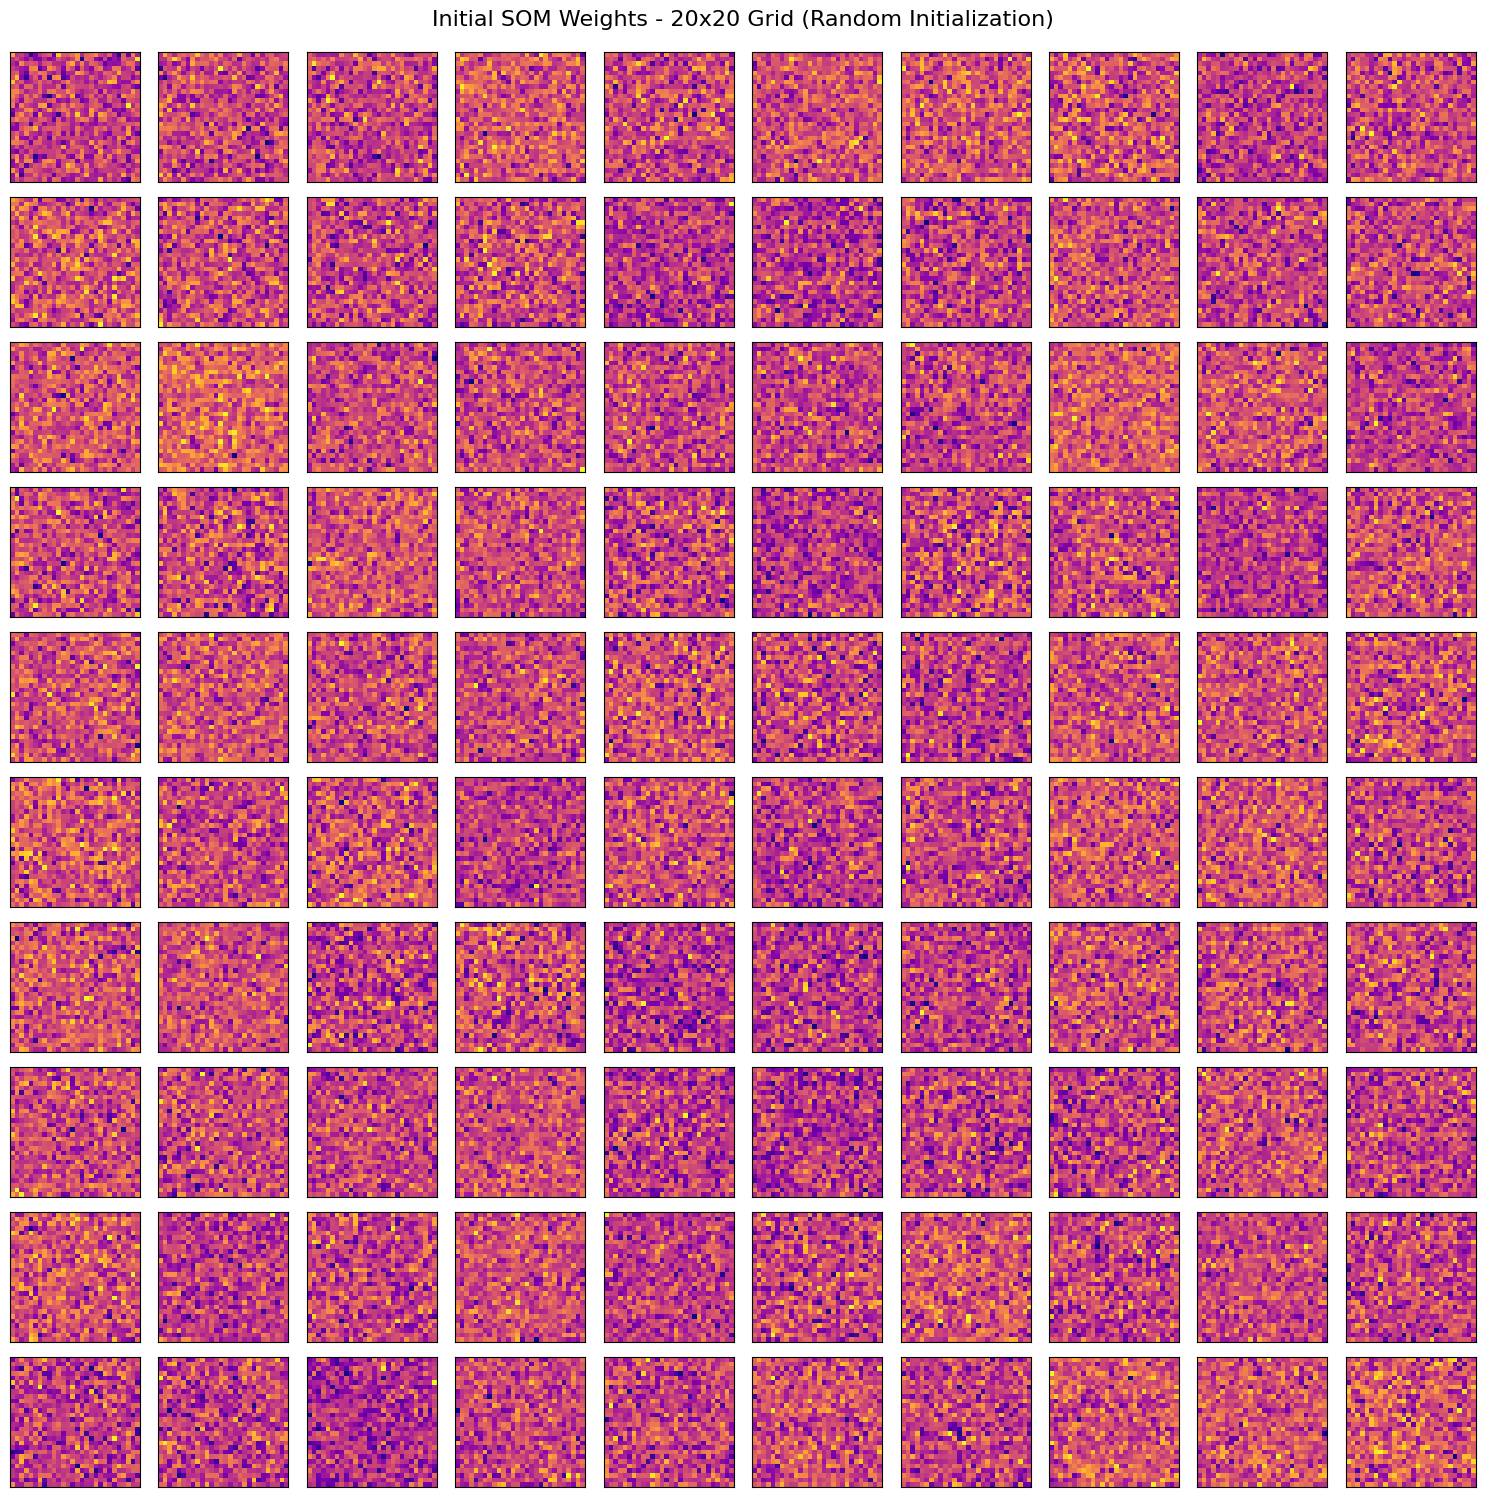


Training 20x20 SOM for 100 epochs...


Epochs:  49%|████▉     | 49/100 [27:10<15:20, 18.04s/it, eta=0.0082, sigma=0.82, width=3]   


50% Half-completed Training SOM with 20x20 grid for 100 epochs...

Shape: (20, 20, 784)



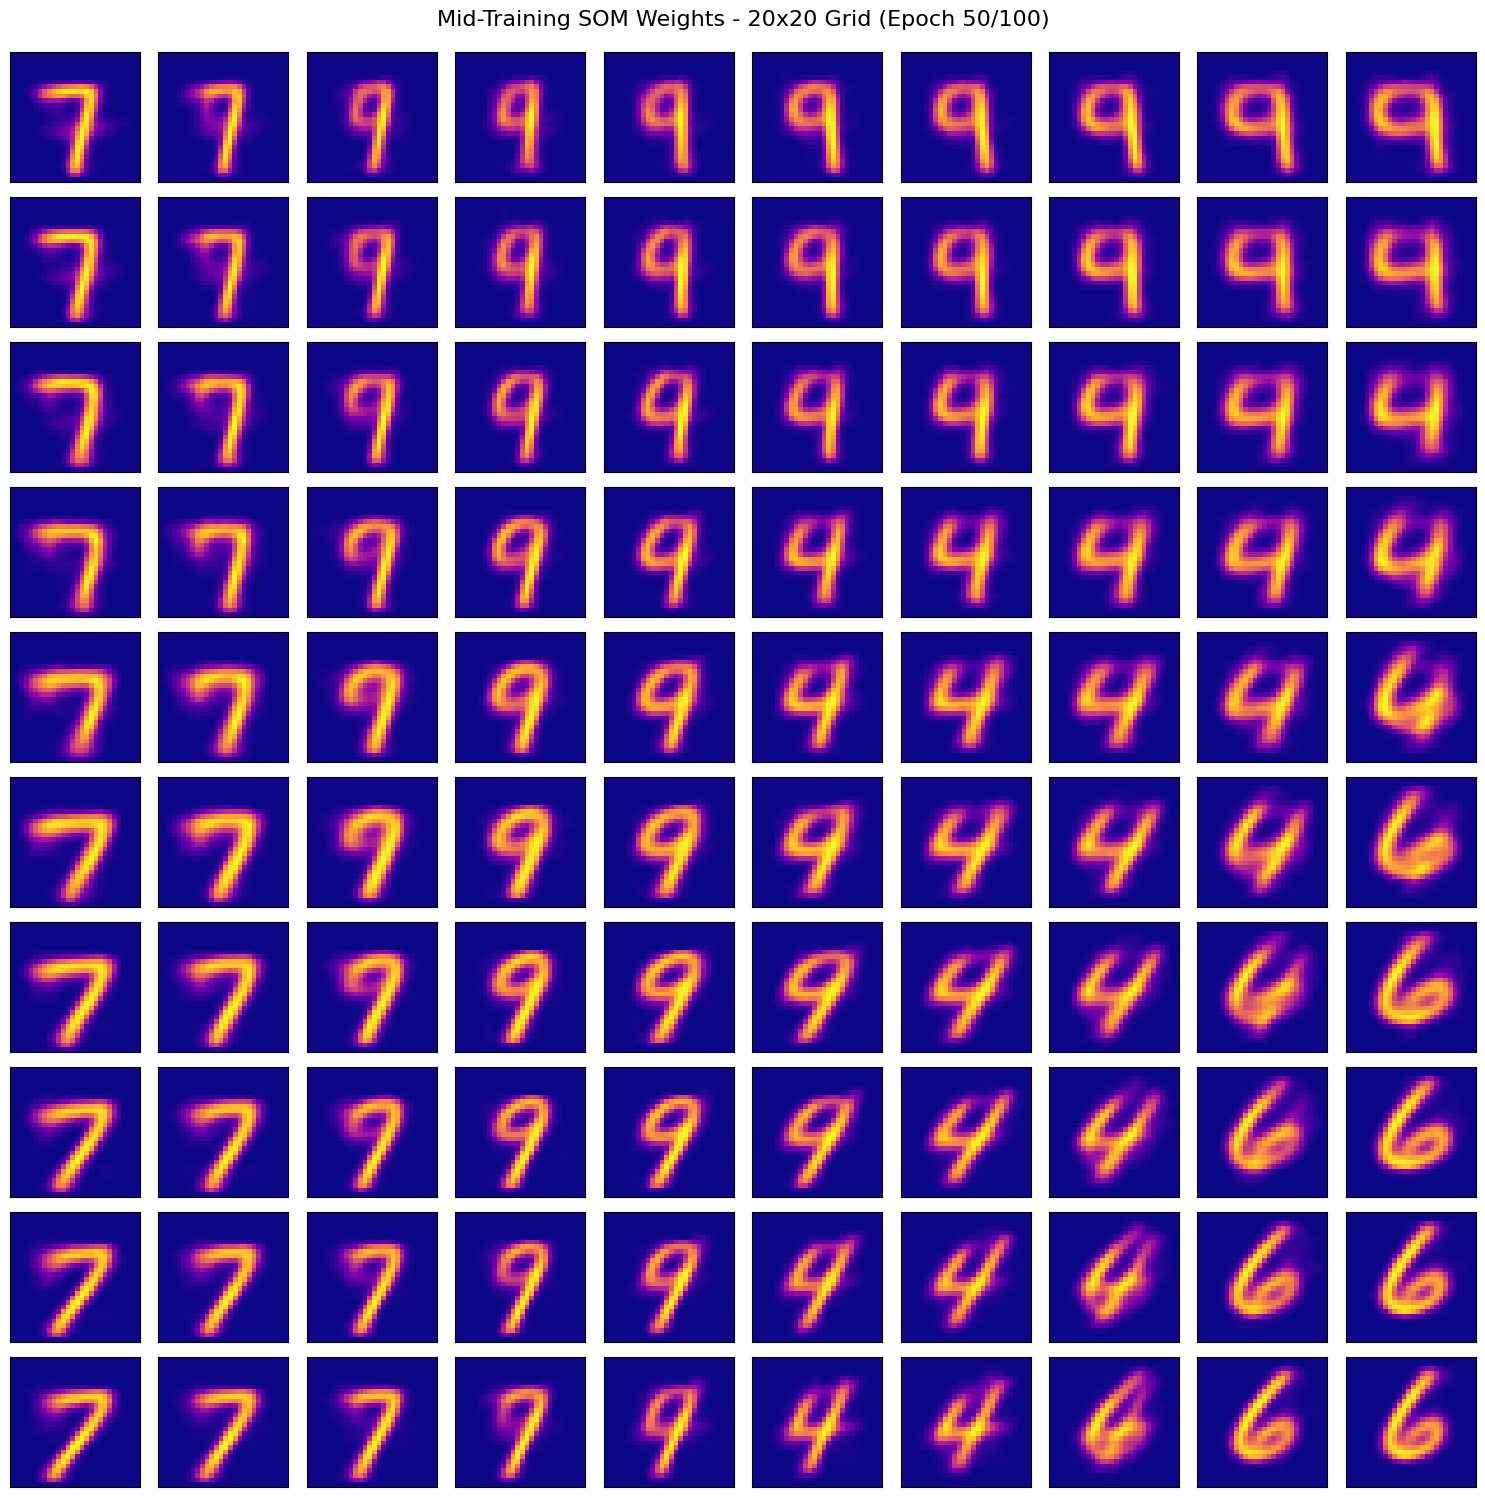

Epochs:  99%|█████████▉| 99/100 [39:05<00:12, 12.82s/it, eta=0.0007, sigma=0.07, width=1]


100% Completed Training SOM with 20x20 grid for 100 epochs...

Shape: (20, 20, 784)



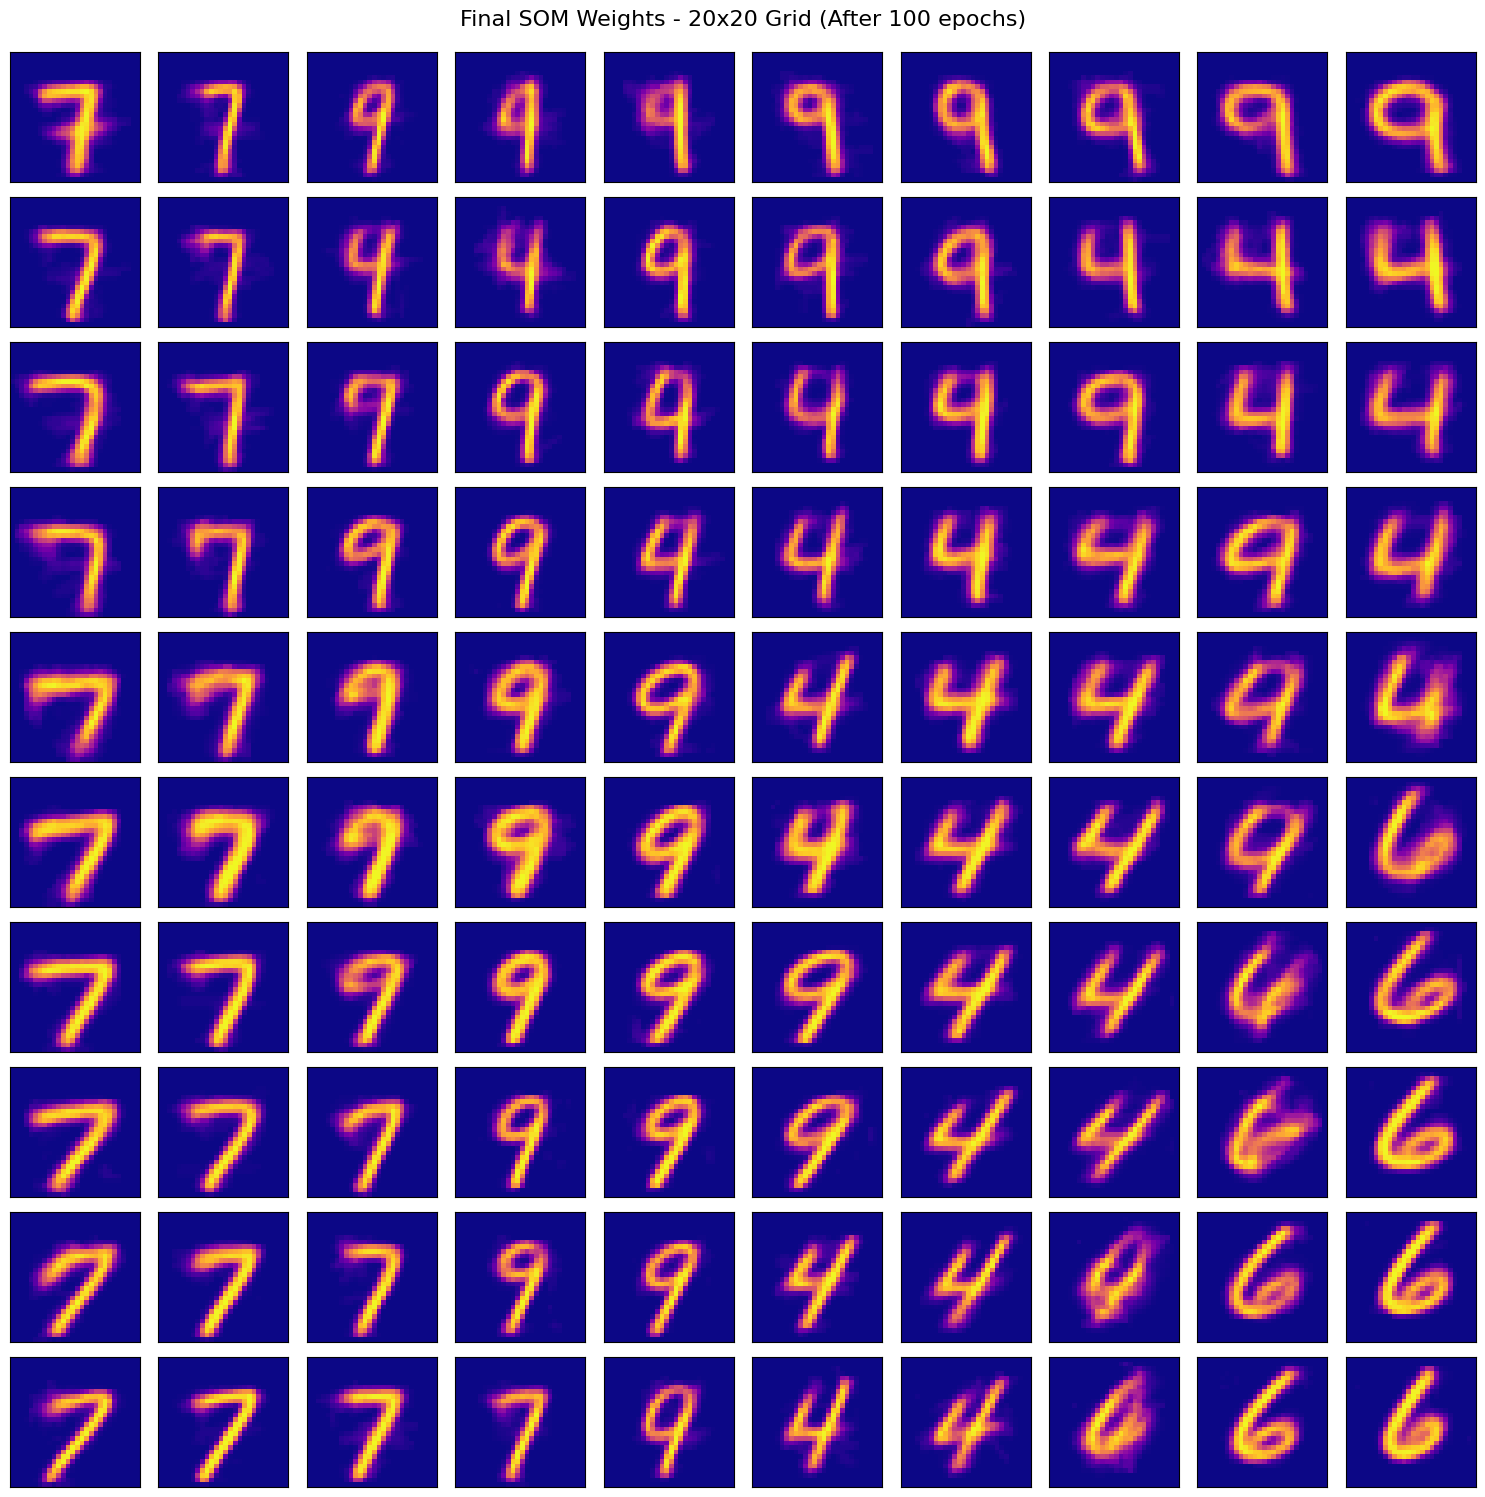

Epochs: 100%|██████████| 100/100 [39:22<00:00, 23.62s/it, eta=0.0007, sigma=0.07, width=1]


SOM weights have been saved to SOM_train_20x20.npy

Training time for 20x20 SOM: 39.42 minutes

Evaluating 20x20 SOM on Training Set...

20x20 SOM - Training Accuracy: 0.8883

20x20 SOM - Training Set Confusion Matrix:
[[ 965    0    2    2    0   14   17    0    1    0]
 [   0 1101   12    5    3    2    0    1    2    1]
 [   8   17  909   14   13    2    6    5   13    4]
 [   5    6   21  861    1   82    2   10   37    7]
 [   2   11   14    2  819    0    5   13    2  112]
 [   8    3    6   37    1  763   11    1   27    6]
 [  18    4    0    0    7    6  973    0    6    0]
 [   0   11    5    2   35    4    1  930    0   82]
 [  12   10   15   54    4   52   14    5  769    9]
 [   5    2    3   13  103    8    8   39    4  793]]
Training Accuracy: 0.8883


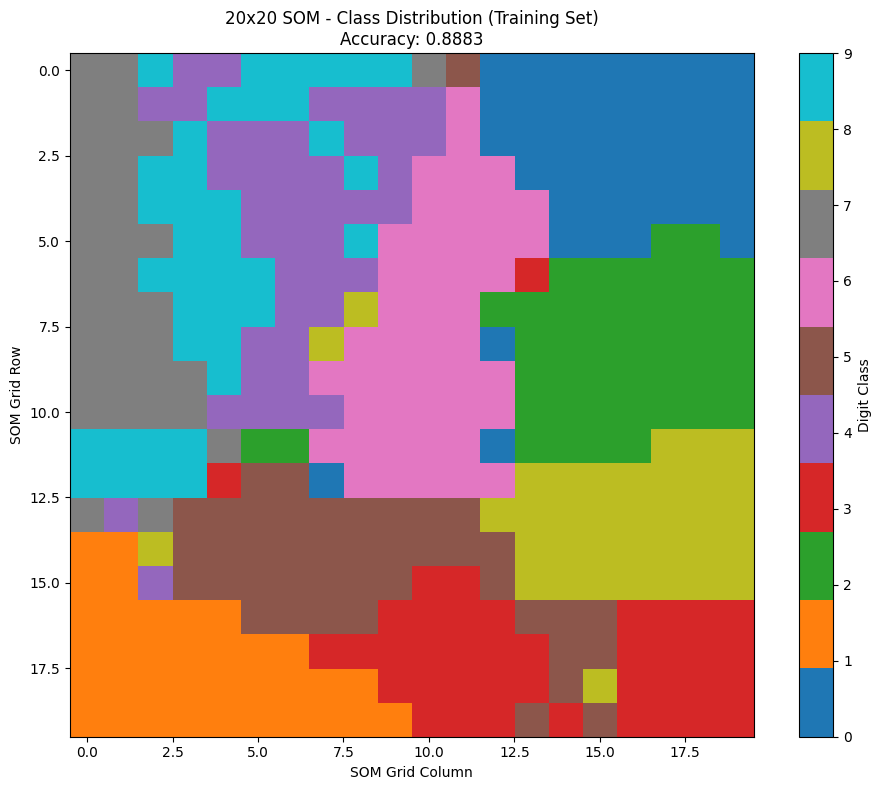


Evaluating 20x20 SOM on Test Set...

20x20 SOM - Test Accuracy: 0.8911

20x20 SOM - Test Set Confusion Matrix:
[[ 950    1    7    2    1    8    9    1    1    0]
 [   0 1123    6    0    0    2    3    0    0    1]
 [  12    3  948   24    3    3    4   14   20    1]
 [   2    1   19  874    0   69    2    8   27    8]
 [   5    8   13    2  818    1    5    6    1  123]
 [   9    4    5   44    1  780   11    2   24   12]
 [  19    4    6    1    8   14  904    0    2    0]
 [   1   22   13    6   26    0    0  904    1   55]
 [  15    1   17   59    6   62    9    9  782   14]
 [   8    8    4   13   94    8    3   39    4  828]]
Test Accuracy: 0.8911


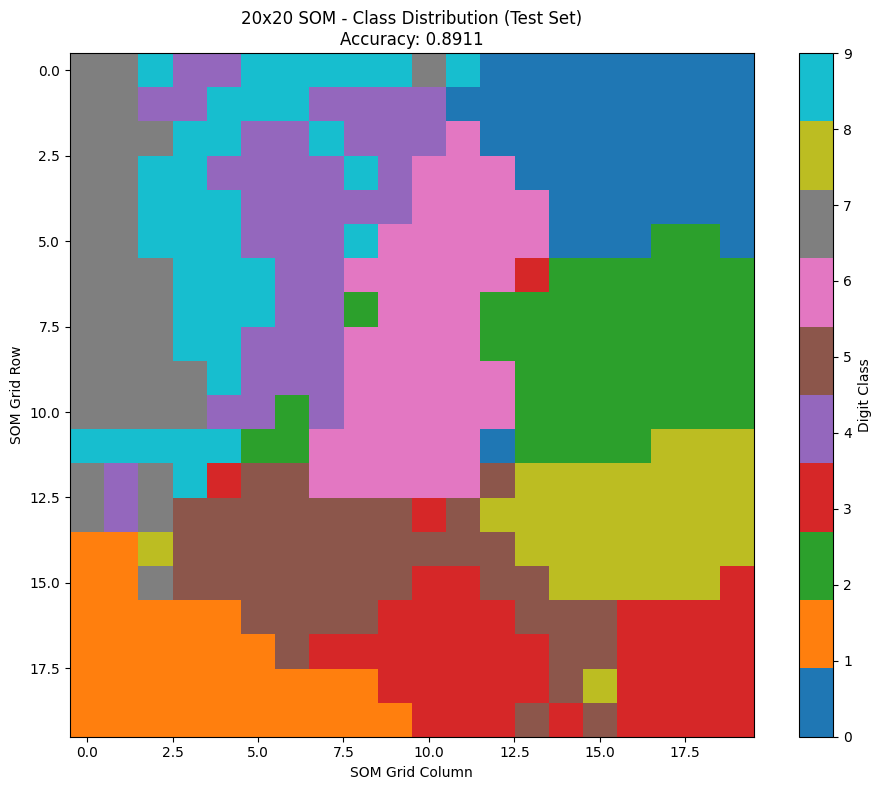

Completed evaluation for 20x20 SOM.

Training Accuracy: 0.8883, Test Accuracy: 0.8911
, Training Time: 39.42 minutes


Training SOM with 40x40 grid...

Initial SOM weights for 40x40 grid
Shape: (40, 40, 784)



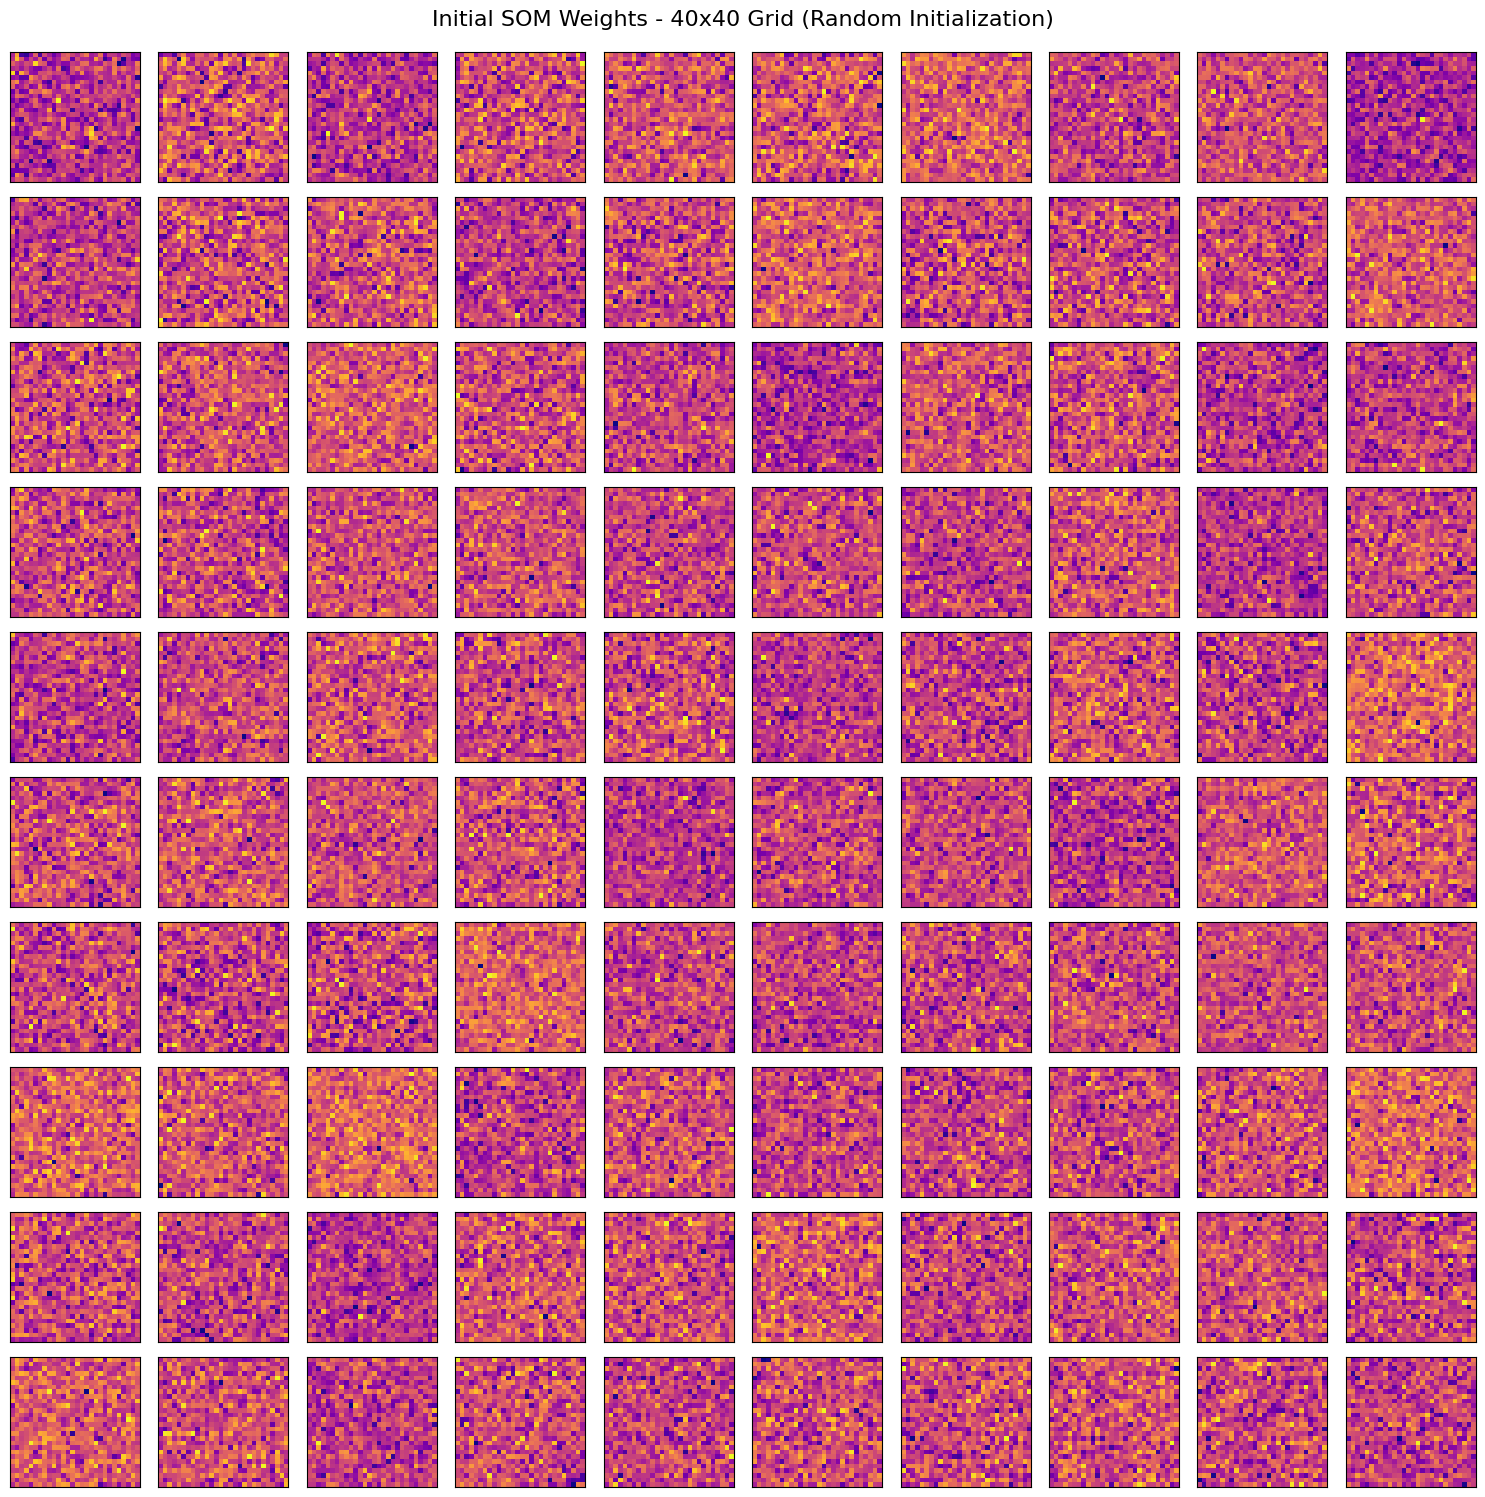


Training 40x40 SOM for 100 epochs...


Epochs:  49%|████▉     | 49/100 [10:45:54<1:16:23, 89.88s/it, eta=0.0082, sigma=1.64, width=5]    


50% Half-completed Training SOM with 40x40 grid for 100 epochs...

Shape: (40, 40, 784)



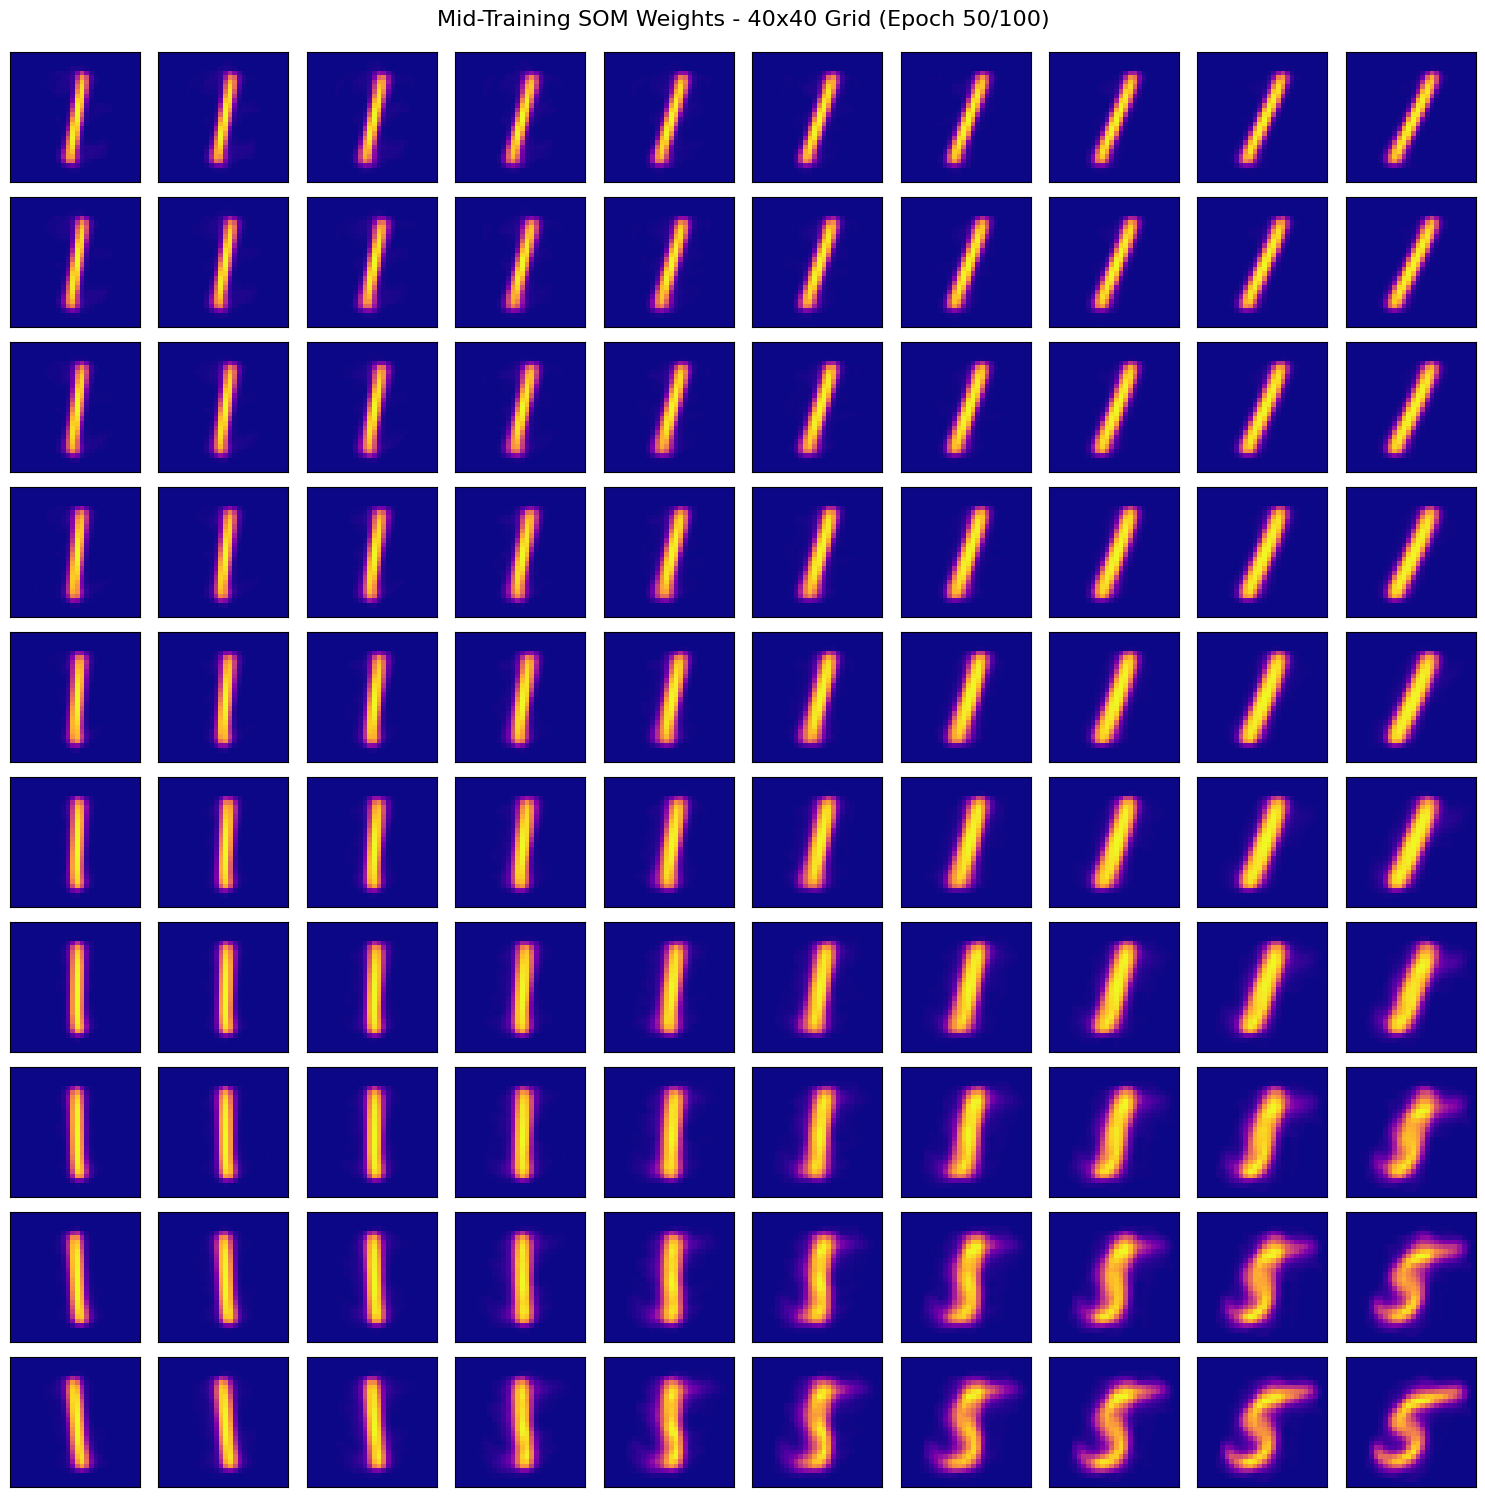

Epochs:  99%|█████████▉| 99/100 [12:02:17<01:28, 88.28s/it, eta=0.0007, sigma=0.13, width=1]  


100% Completed Training SOM with 40x40 grid for 100 epochs...

Shape: (40, 40, 784)



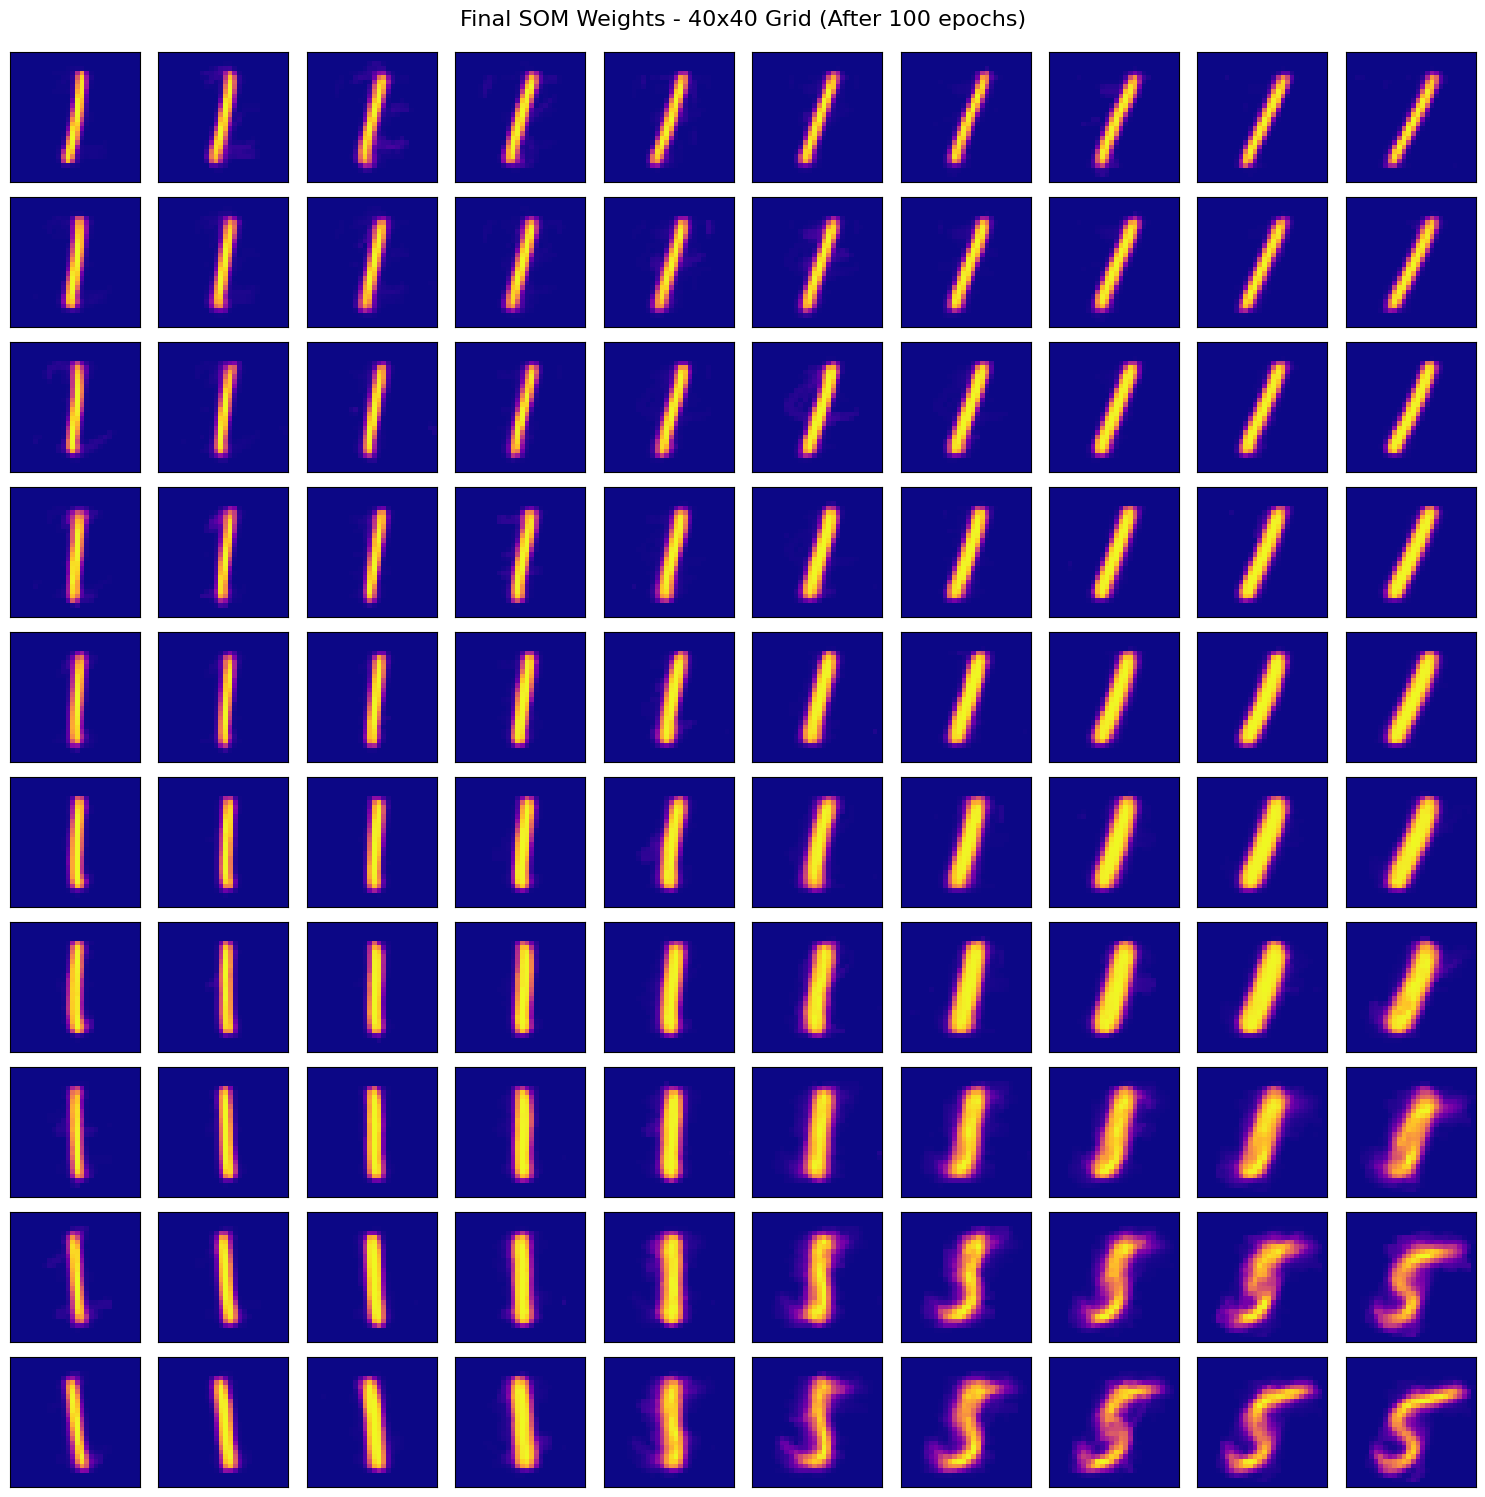

Epochs: 100%|██████████| 100/100 [12:03:52<00:00, 434.32s/it, eta=0.0007, sigma=0.13, width=1]


SOM weights have been saved to SOM_train_40x40.npy

Training time for 40x40 SOM: 723.91 minutes

Evaluating 40x40 SOM on Training Set...

40x40 SOM - Training Accuracy: 0.9131

40x40 SOM - Training Set Confusion Matrix:
[[ 980    0    2    0    0    5   12    1    0    1]
 [   0 1101   11    3    6    1    2    1    2    0]
 [   9   14  926   10    4    2    2    8   16    0]
 [   6    3   19  920    4   38    2   11   19   10]
 [   1    7    2    4  860    3    8    4    1   90]
 [  10    0    1   34    3  782    8    2   18    5]
 [  17    1    2    1    3   11  979    0    0    0]
 [   1    8   10    1   36    2    0  967    1   44]
 [  10    4    7   46   13   33    9    7  806    9]
 [   5    2    2   12  105    2    2   32    6  810]]
Training Accuracy: 0.9131


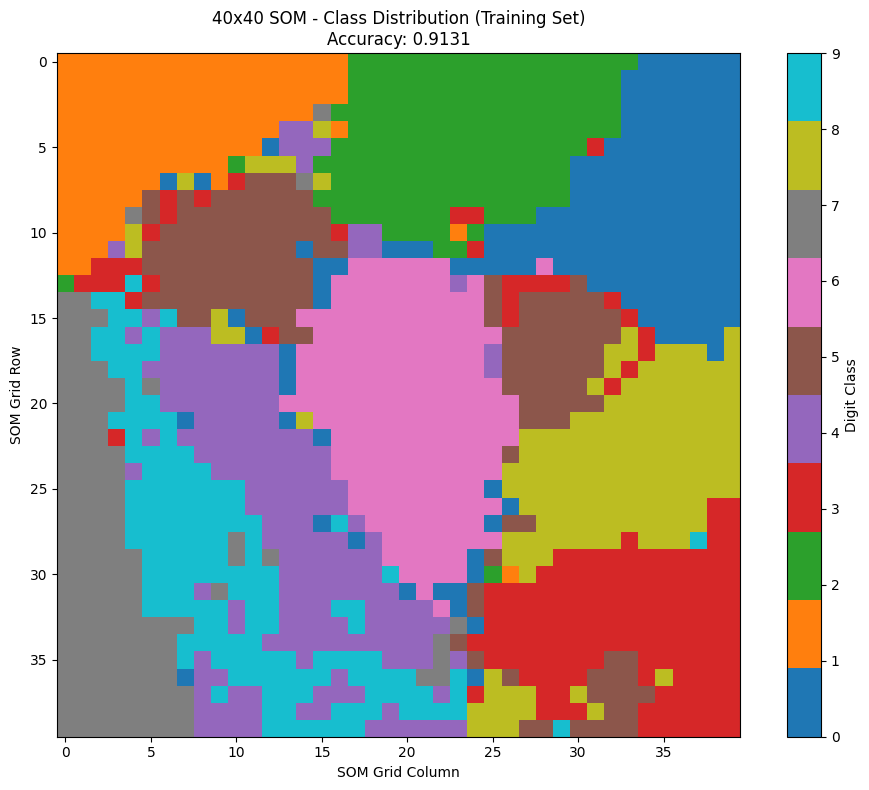


Evaluating 40x40 SOM on Test Set...

40x40 SOM - Test Accuracy: 0.9212

40x40 SOM - Test Set Confusion Matrix:
[[ 955    1    7    0    0    5    9    1    2    0]
 [   0 1122    4    1    0    2    3    1    1    1]
 [  11    2  980    3    2    2    5   12   15    0]
 [   3    2   15  932    1   21    0   12   20    4]
 [   3    8    4    0  871    2    7    9    0   78]
 [   6    2    2   43    3  811    8    1   11    5]
 [  18    1    4    5    7    9  912    0    2    0]
 [   0   17   17    3   23    2    0  927    1   38]
 [   7    1   13   43   10   41    2    8  838   11]
 [   6    2    4   12   76    7    1   31    6  864]]
Test Accuracy: 0.9212


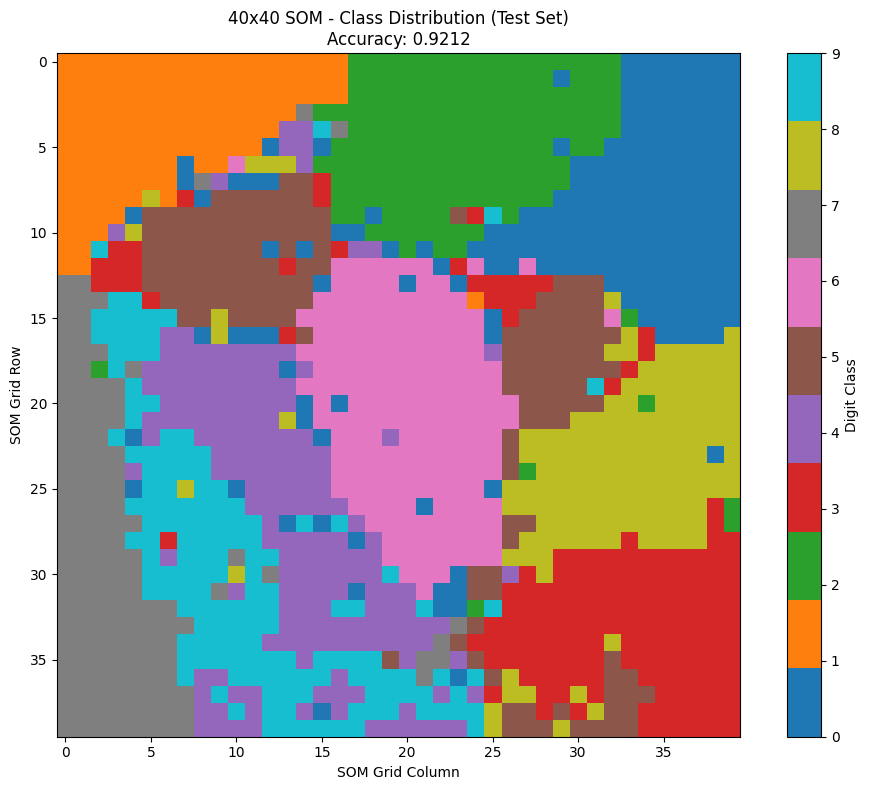

Completed evaluation for 40x40 SOM.

Training Accuracy: 0.9131, Test Accuracy: 0.9212
, Training Time: 723.91 minutes


Training SOM with 80x80 grid...

Training 80x80 SOM for 100 epochs...


Epochs: 100%|██████████| 100/100 [16:47:01<00:00, 604.22s/it, eta=0.0007, sigma=0.27, width=1]     


SOM weights have been saved to SOM_train_80x80.npy

Training time for 80x80 SOM: 1007.03 minutes

Evaluating 80x80 SOM on Training Set...

80x80 SOM - Training Accuracy: 0.9456

80x80 SOM - Training Set Confusion Matrix:
[[ 995    1    0    0    0    2    2    1    0    0]
 [   0 1120    3    0    2    0    0    0    1    1]
 [   4    9  962    2    3    1    0    7    3    0]
 [   5    3   17  966    1   11    0   12   13    4]
 [   1    6    5    2  941    0    0    2    1   22]
 [   5    1    2   37    3  804    3    0    6    2]
 [  14    3    1    0    4    7  984    0    1    0]
 [   0    8    7    0   17    1    0 1016    0   21]
 [   4    9   16   34   11   36    4    9  817    4]
 [   4    3    6   16   51    5    0   39    3  851]]
Training Accuracy: 0.9456


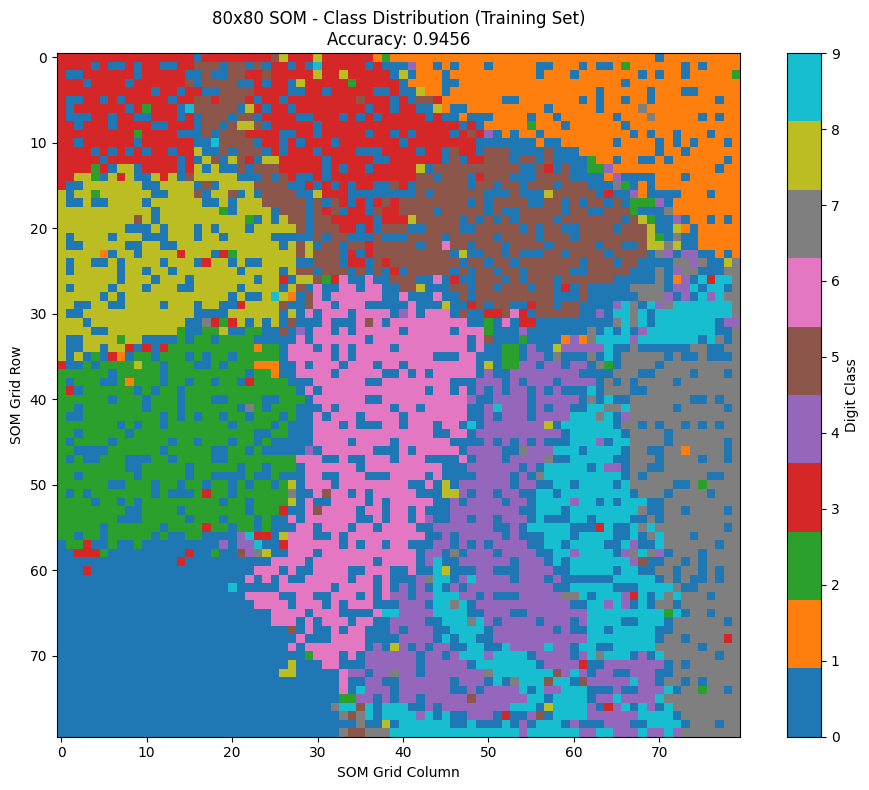


Evaluating 80x80 SOM on Test Set...

80x80 SOM - Test Accuracy: 0.9518

80x80 SOM - Test Set Confusion Matrix:
[[ 972    1    1    0    0    1    4    0    1    0]
 [   0 1130    2    0    0    0    1    1    0    1]
 [   9    2 1001    6    0    0    2    6    6    0]
 [   1    2   13  950    0   15    1    7   16    5]
 [   2    4    3    0  943    0    3    1    2   24]
 [   3    0    3   21    3  848    2    2    8    2]
 [  12    3    1    0    1    5  936    0    0    0]
 [   1   10   15    3   13    0    0  971    1   14]
 [   8    2   18   32    7   24    4    6  870    3]
 [   4    2    2   12   54    2    1   27    8  897]]
Test Accuracy: 0.9518


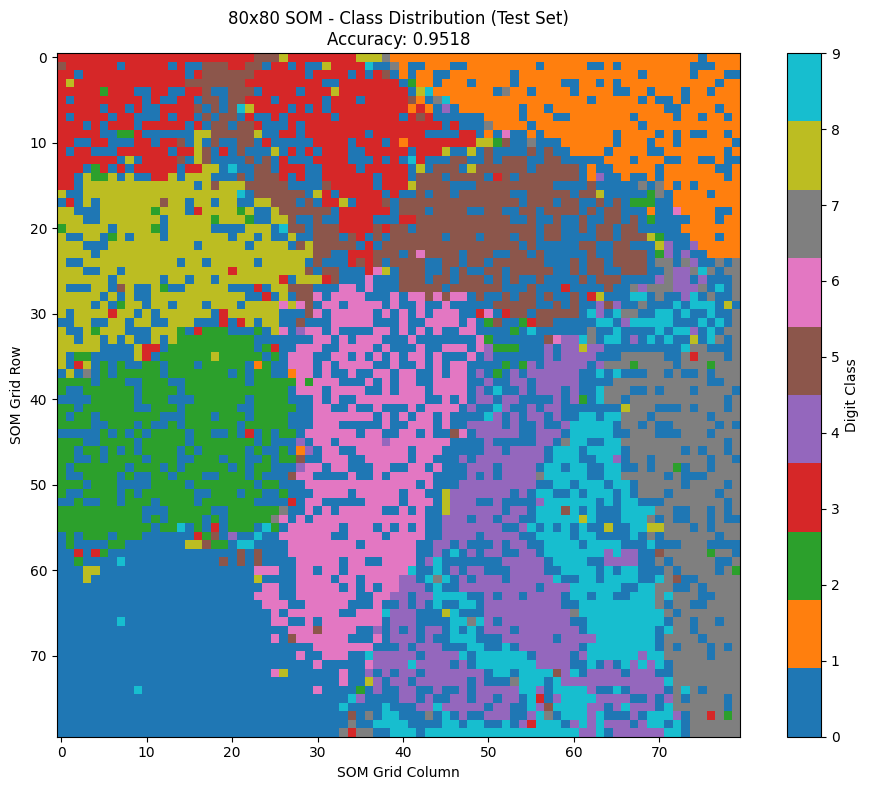

Completed evaluation for 80x80 SOM.

Training Accuracy: 0.9456, Test Accuracy: 0.9518
, Training Time: 1007.03 minutes



In [13]:
# Train and evaluate SOMs with different grid sizes
grid_sizes = [20, 40, 80]
results = {}

for grid_size in grid_sizes:
    start_time = time.time()
    
    som, initial_weights, mid_weights = train_som_with_grid_size(grid_size, retrain=False)
    
    training_time = time.time() - start_time
    print(f"Training time for {grid_size}x{grid_size} SOM: {training_time/60:.2f} minutes")
    
    training_accuracy, training_cm = evaluate_som_on_dataset(som, Tr_set, Ltr_set, grid_size, dataset_type='Training')
    test_accuracy, test_cm = evaluate_som_on_dataset(som, Test_set, Ltest_set, grid_size, dataset_type='Test')
    
    results[grid_size] = {
        'som': som,
        'training_accuracy': training_accuracy,
        'test_accuracy': test_accuracy,
        'training_time': training_time
    }
    
    print(f"Completed evaluation for {grid_size}x{grid_size} SOM.\n")
    print(f"Training Accuracy: {training_accuracy:.4f}, Test Accuracy: {test_accuracy:.4f}\n, Training Time: {training_time/60:.2f} minutes\n")

### Experimenting with different learning rates

In [14]:
# Experiment with different learning rates
learning_rates = [0.01, 0.05, 0.1, 0.5]
grid_size = 20
nclasses = np.max(Ltr_set) + 1

print("\n=== Experimenting with Learning Rates ===")
for lr in learning_rates:
    print(f"\nTraining with learning rate: {lr}")
    som_lr, _, _ = SOM(
        dispRes=[28, 28],
        trainingData=Tr_set,
        ndim=grid_size,
        nepochs=100,
        eta0=lr,
        etadecay=0.05,
        sgm0=10,
        sgmdecay=0.05,
        showMode=0
    )
    
    filename = f"SOM_train_{grid_size}x{grid_size}_lr{lr}.npy"
    np.save(filename, som_lr)
    print(f"SOM weights with learning rate {lr} have been saved to {filename}\n")
    
    grid_color = np.zeros((grid_size, grid_size))
    cm = np.zeros((nclasses+1, nclasses+1))
    grid_color, cm = SOM_Test(Tr_set, som_lr, Ltr_set, grid_color, cm, grid_size)
    accuracy = np.trace(cm) / np.sum(cm)
    print(f"Learning rate {lr}: Training Accuracy = {accuracy:.4f}")


=== Experimenting with Learning Rates ===

Training with learning rate: 0.01

Training 20x20 SOM for 100 epochs...


Epochs: 100%|██████████| 100/100 [2:23:08<00:00, 85.88s/it, eta=0.0001, sigma=0.07, width=1]     


SOM weights with learning rate 0.01 have been saved to SOM_train_20x20_lr0.01.npy

Learning rate 0.01: Training Accuracy = 0.8542

Training with learning rate: 0.05

Training 20x20 SOM for 100 epochs...


Epochs: 100%|██████████| 100/100 [23:37<00:00, 14.18s/it, eta=0.0003, sigma=0.07, width=1] 


SOM weights with learning rate 0.05 have been saved to SOM_train_20x20_lr0.05.npy

Learning rate 0.05: Training Accuracy = 0.8814

Training with learning rate: 0.1

Training 20x20 SOM for 100 epochs...


Epochs: 100%|██████████| 100/100 [21:56<00:00, 13.16s/it, eta=0.0007, sigma=0.07, width=1]


SOM weights with learning rate 0.1 have been saved to SOM_train_20x20_lr0.1.npy

Learning rate 0.1: Training Accuracy = 0.8883

Training with learning rate: 0.5

Training 20x20 SOM for 100 epochs...


Epochs: 100%|██████████| 100/100 [25:22<00:00, 15.23s/it, eta=0.0034, sigma=0.07, width=1]


SOM weights with learning rate 0.5 have been saved to SOM_train_20x20_lr0.5.npy

Learning rate 0.5: Training Accuracy = 0.9050


### Experimenting with different neighborhood decay functions

In [15]:
# Experiment with different neighborhood decay rates
sgm_decays = [0.01, 0.05, 0.1, 0.2]

print("\n=== Experimenting with Neighborhood Decay ===")
for sgm_decay in sgm_decays:
    print(f"\nTraining with neighborhood decay: {sgm_decay}")
    som_sgm, _, _ = SOM(
        dispRes=[28, 28],
        trainingData=Tr_set,
        ndim=grid_size,
        nepochs=100,
        eta0=0.1,
        etadecay=0.05,
        sgm0=10,
        sgmdecay=sgm_decay,
        showMode=0
    )
    
    filename = f"SOM_train_{grid_size}x{grid_size}_sgmdecay{sgm_decay}.npy"
    np.save(filename, som_sgm)
    print(f"SOM weights with neighborhood decay {sgm_decay} have been saved to {filename}\n")
    
    grid_color = np.zeros((grid_size, grid_size))
    cm = np.zeros((nclasses+1, nclasses+1))
    grid_color, cm = SOM_Test(Tr_set, som_sgm, Ltr_set, grid_color, cm, grid_size)
    accuracy = np.trace(cm) / np.sum(cm)
    print(f"Neighborhood decay {sgm_decay}: Training Accuracy = {accuracy:.4f}")


=== Experimenting with Neighborhood Decay ===

Training with neighborhood decay: 0.01

Training 20x20 SOM for 100 epochs...


Epochs: 100%|██████████| 100/100 [47:38<00:00, 28.58s/it, eta=0.0007, sigma=3.68, width=12]


SOM weights with neighborhood decay 0.01 have been saved to SOM_train_20x20_sgmdecay0.01.npy

Neighborhood decay 0.01: Training Accuracy = 0.6913

Training with neighborhood decay: 0.05

Training 20x20 SOM for 100 epochs...


Epochs: 100%|██████████| 100/100 [22:42<00:00, 13.63s/it, eta=0.0007, sigma=0.07, width=1]


SOM weights with neighborhood decay 0.05 have been saved to SOM_train_20x20_sgmdecay0.05.npy

Neighborhood decay 0.05: Training Accuracy = 0.8883

Training with neighborhood decay: 0.1

Training 20x20 SOM for 100 epochs...


Epochs: 100%|██████████| 100/100 [18:59<00:00, 11.40s/it, eta=0.0007, sigma=0.00, width=1]


SOM weights with neighborhood decay 0.1 have been saved to SOM_train_20x20_sgmdecay0.1.npy

Neighborhood decay 0.1: Training Accuracy = 0.8991

Training with neighborhood decay: 0.2

Training 20x20 SOM for 100 epochs...


Epochs: 100%|██████████| 100/100 [16:05<00:00,  9.66s/it, eta=0.0007, sigma=0.00, width=1]


SOM weights with neighborhood decay 0.2 have been saved to SOM_train_20x20_sgmdecay0.2.npy

Neighborhood decay 0.2: Training Accuracy = 0.9110


Question: <b>What is a biological neuron? How does it relate to the concept of neurons in
SOM?</b><br>
A biological neuron is a specialized cell in the nervous system that transmits information through electrical and chemical signals. It consists of three main parts: the cell body (soma), dendrites, and an axon. Dendrites receive incoming signals from other neurons, while the axon transmits signals to other neurons or muscles. The communication between neurons occurs at synapses, where neurotransmitters are released to propagate the signal.<br>

In the context of SOMs, neurons are artificial units that mimic the behavior of biological neurons. Each neuron in a SOM is associated with a weight vector that represents a point in the input space. During the training process, these artificial neurons compete to respond to input data, similar to how biological neurons compete to respond to stimuli. The winning neuron (Best Matching Unit) and its neighbors adjust their weights to better represent the input data, leading to the formation of a topological map that preserves the spatial relationships of the input data. Essentially, biological neurons operate through complex biochemical processes while SOM neurons function through algorithms that simulate learning and adaptation.